# Modelo: sensibilidad de la demanda a la temperatura

**Pregunta:** ¿cuánto cambia la demanda eléctrica diaria de la Península con el frío y con el calor?

El modelo al que quiero llegar es este:

```
D_t = β0 + β_h·HDD_t + β_c·CDD_t
         + Σ γ_d · 1[día_semana_t = d]    d = martes … domingo
         + δ · festivo_t
         + Σ λ_a · 1[año_t = a]           a = 2022 … 2025
         + ε_t
```

| Término | Qué recoge | Cómo se lee |
|---|---|---|
| β0 | nivel base | demanda de un **lunes laborable de 2021** a T_base |
| β_h | frío | MWh extra por cada grado-día por debajo de T_base |
| β_c | calor | MWh extra por cada grado-día por encima de T_base |
| γ_d | día de la semana | diferencia en MWh respecto al **lunes** |
| δ | festivo | diferencia en MWh de un festivo respecto a un laborable |
| λ_a | año | diferencia de nivel respecto a **2021** (crisis energética, turismo, autoconsumo…) |
| ε_t | error | todo lo que el modelo no explica |

**Categorías de referencia:** si meto las 7 dummies de día, en cada fila suman 1, igual que la constante: colinealidad perfecta.

 `C()` quita la primera categoría (lunes, 2021) y el resto de coeficientes se leen respecto a ella.

T_base es fija (17 °C en la Península y 16 °C en las islas, del EDA), así que el modelo sigue siendo lineal en los β y se estima por MCO.

No lo meto todo de golpe: empiezo solo con la temperatura y añado cada pieza cuando una gráfica de los residuos muestra que hace falta. Este cuaderno es solo la Península. El mismo modelo aplicado a Baleares y Canarias, y la comparación de los tres sistemas, están en `03_comparacion_sistemas.ipynb`.

In [39]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import durbin_watson

RAIZ = Path.cwd().parent          # Jupyter arranca en notebooks/, así que subo un nivel
sys.path.append(str(RAIZ / "src"))

from config import FIGURAS
from features import CONFIG, cargar_sistema, crear_features
from modelo import (
    ajustar_modelo,
    efectos_en_porcentaje,
    formula_sistema,
    residuos_por_mes,
)

FIGURAS.mkdir(parents=True, exist_ok=True)
NOMBRES_MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

#Un grafico de los residuos que usaré varias veces.
def plot_residuos(res, titulo):
    """Residuos de todo el periodo y un zoom a octubre-noviembre de 2023."""
    residuos = res.resid
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    axes[0].plot(residuos.index, residuos, linewidth=0.5)
    axes[0].set_title(f"Residuos del {titulo}, todo el periodo")

    zoom = residuos.loc["2023-10":"2023-11"]
    axes[1].plot(zoom.index, zoom, marker="o", markersize=4, linewidth=1)
    axes[1].set_title("Zoom: octubre-noviembre 2023")

    for ax in axes:
        ax.axhline(0, color="black", linewidth=1)
        ax.set_ylabel("Residuo (MWh)")
    plt.tight_layout()
    plt.show()

#cargo los datos del sistema=peninsular
df_peninsular = crear_features(cargar_sistema("peninsular"), **CONFIG["peninsular"])
demanda_media = df_peninsular["demanda_mwh"].mean()
t_base = CONFIG["peninsular"]["t_base"]

## Modelo A: solo temperatura

`demanda ~ hdd + cdd`

In [40]:
modelo_a = smf.ols("demanda_mwh ~ hdd + cdd", data=df_peninsular).fit()
print(modelo_a.params.round(1))
print(f"R² = {modelo_a.rsquared:.3f}")
print(f"SD del residuo = {modelo_a.resid.std():,.0f} MWh".replace(",", " ")) # es la desviación media de los residuos

Intercept    584531.9
hdd           11980.4
cdd           10731.5
dtype: float64
R² = 0.304
SD del residuo = 55 314 MWh


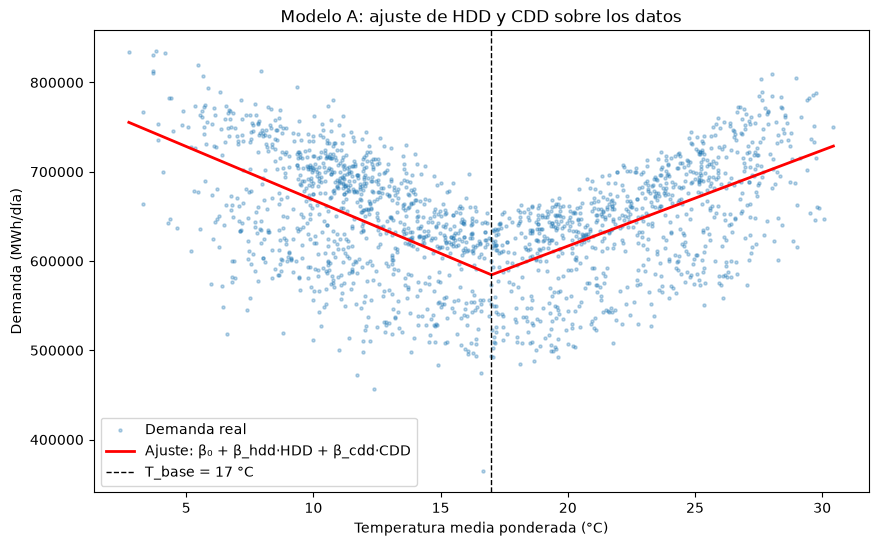

In [41]:
# ajuste sobre los datos, ordenando por temperatura para que la línea se pinte bien
orden = df_peninsular["temperatura"].sort_values().index

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_peninsular["temperatura"], df_peninsular["demanda_mwh"], s=5, alpha=0.3, label="Demanda real")
ax.plot(df_peninsular.loc[orden, "temperatura"], modelo_a.fittedvalues.loc[orden], color="red", linewidth=2,
        label="Ajuste: β₀ + β_hdd·HDD + β_cdd·CDD")
ax.axvline(t_base, color="black", linestyle="--", linewidth=1, label=f"T_base = {t_base} °C")  # aquí HDD = CDD = 0

ax.set_xlabel("Temperatura media ponderada (°C)")
ax.set_ylabel("Demanda (MWh/día)")
ax.set_title("Modelo A: ajuste de HDD y CDD sobre los datos")
ax.legend()
plt.show()

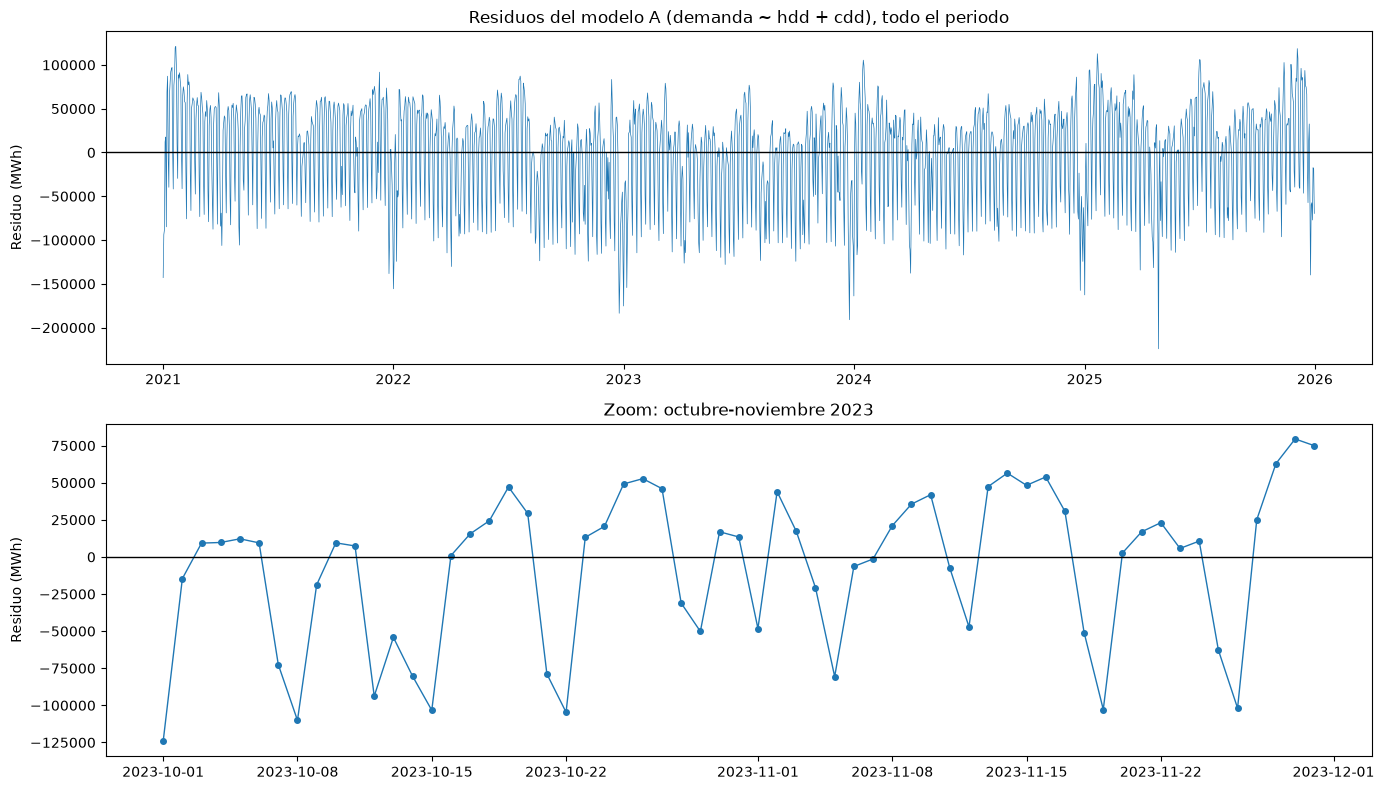

In [42]:
plot_residuos(modelo_a, "modelo A (demanda ~ hdd + cdd)")

La V tiene la forma correcta, pero pasa por el medio de dos nubes: los laborables quedan por encima y los fines de semana por debajo (esto es algo que ya habia visto antes y me habia motivado a crear una separación por dias). 

En el zoom de los residuos se ve claramente como existen 5 puntos positivos (toma el 15-Oct y 22-oct, son los laborables) y luego caen (los findes). También hay caídas en los festivos (12 de octubre y 1 de noviembre).

Todo esto motiva a añadir una variable relacionada con el calendario, que permita explicar más cosas.

## Modelo B: + día de la semana y festivo

`demanda ~ hdd + cdd + C(dia_semana) + festivo`

In [43]:
modelo_b = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo", data=df_peninsular).fit()
print(modelo_b.params.round(1))
print(f"R² = {modelo_b.rsquared:.3f}")
print(f"SD del residuo = {modelo_b.resid.std():,.0f} MWh".replace(",", " "))

Intercept             597080.6
C(dia_semana)[T.1]     18076.9
C(dia_semana)[T.2]     22118.9
C(dia_semana)[T.3]     21498.9
C(dia_semana)[T.4]     14292.0
C(dia_semana)[T.5]    -61218.3
C(dia_semana)[T.6]   -100047.7
hdd                    12558.4
cdd                    10879.4
festivo              -120183.0
dtype: float64
R² = 0.801
SD del residuo = 29 590 MWh


### Qué dice el modelo B

El R² pasa de 0,30 a 0,80 y la desviación típica de los residuos baja casi a la mitad (de unos 55 000 a 30 000 MWh). El calendario explica mucha de la variación que el modelo A no podía explicar.
La demanda media de la Península es de unos 648 000 MWh/día:

**¿Cómo se leen los coeficientes?**

Lo más importante es comparar unos a otros y fijarnos en si son positivos o negativos.


| Término | Coeficiente (MWh) | % demanda media | Lectura |
|---|---|---|---|
| Intercept | 597 081 | 92,1 % | un **lunes** laborable a T_base (17 °C) |
| Martes | +18 077 | +2,8 % | |
| Miércoles | +22 119 | +3,4 % | el día de más demanda |
| Jueves | +21 499 | +3,3 % | |
| Viernes | +14 292 | +2,2 % | empieza a bajar |
| Sábado | −61 218 | −9,4 % | |
| Domingo | −100 048 | −15,4 % | el día de menos demanda |
| festivo | −120 183 | −18,5 % | respecto al mismo día si fuera laborable |
| hdd | 12 558 | 1,9 % | por cada grado-día de frío |
| cdd | 10 879 | 1,7 % | por cada grado-día de calor |

- **Los días de la semana se leen respecto al lunes.** El lunes queda por debajo de martes a jueves, seguramente porque la actividad arranca después del fin de semana; el viernes ya baja un poco.

- **Un festivo entre semana se comporta como un domingo**: un miércoles festivo predice 597 081 + 22 119 − 120 183 ≈ 499 000 MWh, prácticamente lo mismo que un domingo (≈ 497 000).

- **β_hdd y β_cdd casi no cambian** respecto al modelo A (11 980 → 12 558 y 10 731 → 10 879).
     - Tiene sentido, porque el día de la semana no tiene nada que ver con la temperatura, así que añadirlo quita ruido pero no corrige el efecto de la temperatura. 
     - Si algún control estuviera relacionado con la temperatura, sí lo movería.
     
- Todos los coeficientes salen con p < 0,001 ( este p-valor quiere decir que es prácticamente imposible que el efecto sea casualidad ), pero estos errores estándar suponen días independientes.
     - Esta idea de días independientes, no me termina de convencer así que lo reviso luego más abajo con HAC.

En la gráfica siguiente separo los días por tipo y comparo cada nube con la V que predice el modelo para ese día.

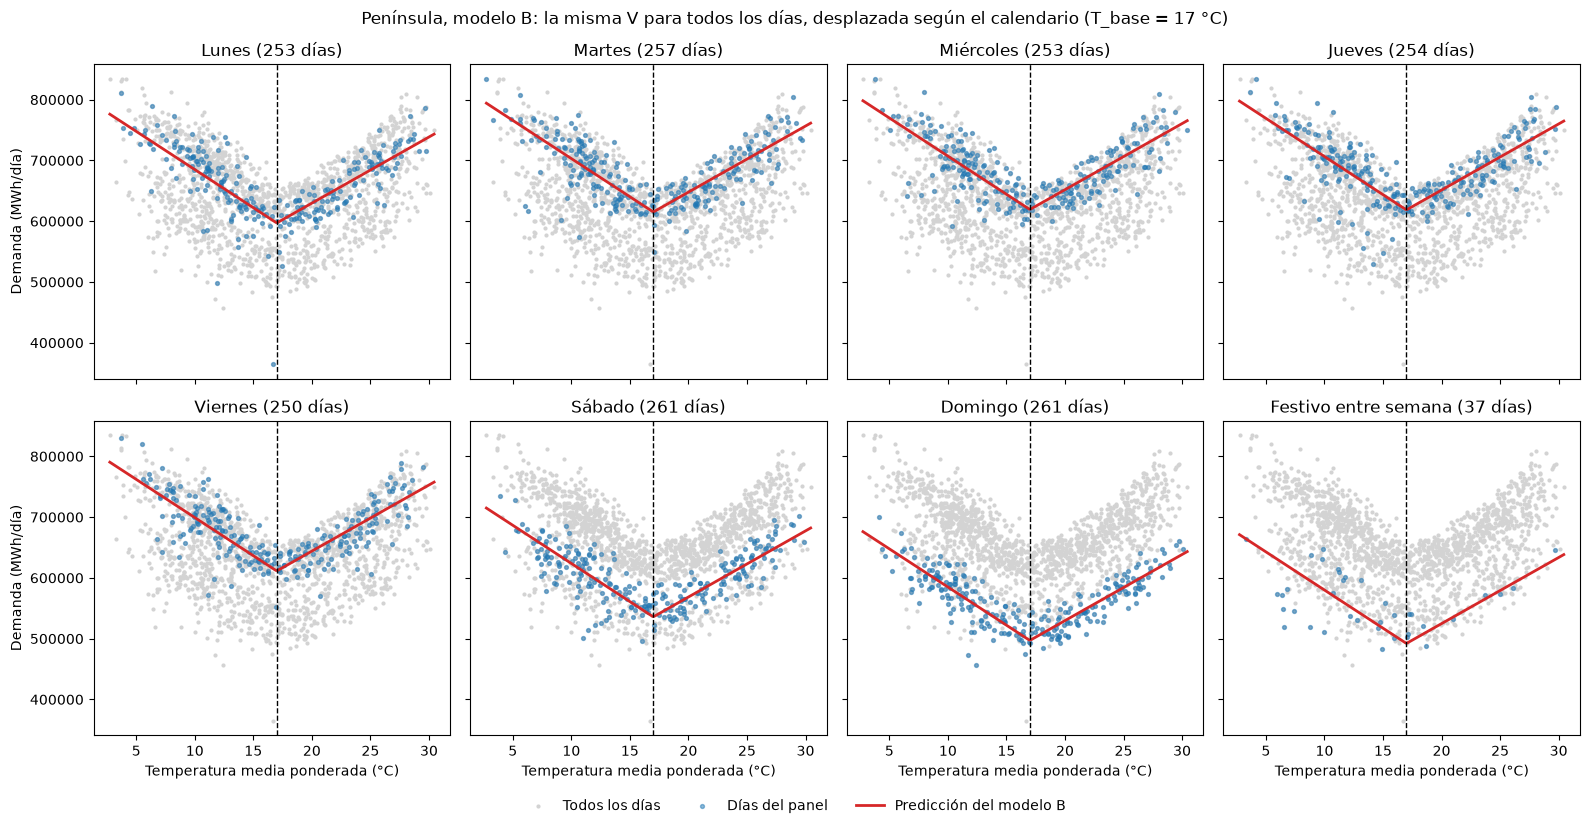

In [44]:
# rejilla de temperaturas y sus HDD/CDD para dibujar la V del modelo
temp = np.linspace(df_peninsular["temperatura"].min(), df_peninsular["temperatura"].max(), 200)
rejilla = pd.DataFrame({"hdd": np.maximum(t_base - temp, 0), "cdd": np.maximum(temp - t_base, 0)})


def predecir(dia_semana, festivo=0):
    """V del modelo B para un día de la semana (0 = lunes) en toda la rejilla."""
    return modelo_b.predict(rejilla.assign(dia_semana=dia_semana, festivo=festivo))


# un panel por tipo de día: (título, qué días son, V que predice el modelo)
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
paneles = [(nombre, (df_peninsular["dia_semana"] == d) & (df_peninsular["festivo"] == 0), predecir(d))
           for d, nombre in enumerate(DIAS)]
# los festivos caen en distintos días: su V es la media de lunes a viernes con festivo = 1
paneles.append(("Festivo entre semana", df_peninsular["festivo"] == 1,
                np.mean([predecir(d, festivo=1) for d in range(5)], axis=0)))

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, (titulo, dias, prediccion) in zip(axes.flat, paneles):
    ax.scatter(df_peninsular["temperatura"], df_peninsular["demanda_mwh"], s=4, color="lightgray",
               label="Todos los días")
    ax.scatter(df_peninsular.loc[dias, "temperatura"], df_peninsular.loc[dias, "demanda_mwh"], s=8, alpha=0.5,
               color="tab:blue", label="Días del panel")
    ax.plot(temp, prediccion, color="tab:red", linewidth=2, label="Predicción del modelo B")
    ax.axvline(t_base, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{titulo} ({dias.sum()} días)")

for ax in axes[1]:
    ax.set_xlabel("Temperatura media ponderada (°C)")
for ax in axes[:, 0]:
    ax.set_ylabel("Demanda (MWh/día)")
fig.suptitle(f"Península, modelo B: la misma V para todos los días, desplazada según el calendario (T_base = {t_base} °C)")
plt.tight_layout()
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.04),
           ncol=3, frameon=False)
fig.savefig(FIGURAS / "modelo_v_peninsular.png", dpi=120, bbox_inches="tight")
plt.show()

**Qué se ve:**
- **De lunes a viernes** las nubes caen encima de su V. El lunes queda un poco más abajo que de martes a jueves, como decían los coeficientes.

- **Sábado y domingo** son la misma V bajada unos 60 000 y 100 000 MWh. El modelo obliga a que la pendiente sea igual en todos los paneles (solo cambia la altura), y los datos parecen aceptarlo.

- **Festivos entre semana** (37 días): su V queda a la altura de la del domingo. Pero no todos los festivos se comportan igual: los de enero (1 y 6) quedan de media unos 42 000 MWh por debajo de la predicción y los de noviembre unos 35 000 por encima. Un solo coeficiente `festivo` es una media de todos ellos.

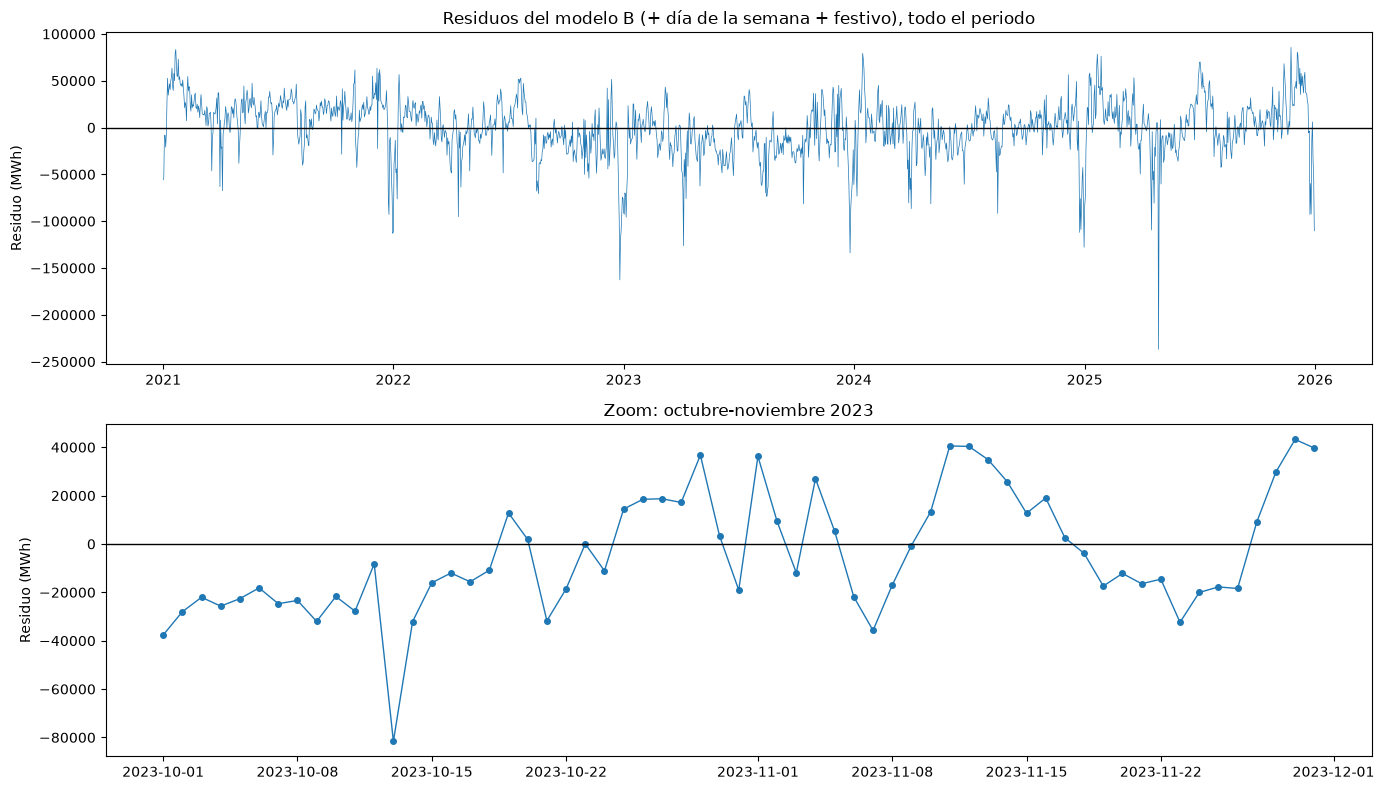

In [45]:
plot_residuos(modelo_b, "modelo B (+ día de la semana + festivo)")

**Qué queda en los residuos:**
- El diente de sierra semanal ha desaparecido: el calendario estaba explicando eso.
- En el zoom, el 12 de octubre ya está bien ajustado (−8 000 MWh), pero el **13 de octubre de 2023** (viernes, puente) cae a −82 000: el modelo no sabe qué es un puente.
- Los peores residuos de todo el periodo son el apagón del 28/04/2025 y días de **Navidad que no son festivos** (24, 26–28 y 31 de diciembre), además del Jueves Santo de 2023, que es festivo autonómico.
- Quedan **olas de varias semanas** por encima o por debajo de 0, y en la gráfica completa 2021 queda casi siempre por encima y 2023 por debajo.

Estos puntos hacen que surgen dos nuevas ideas, ¿importa el año? y ¿existe un fenómeno de olas/conjuntos en los días? 

fecha
2021    2.61
2022   -0.96
2023   -2.09
2024   -0.65
2025    1.09
dtype: float64


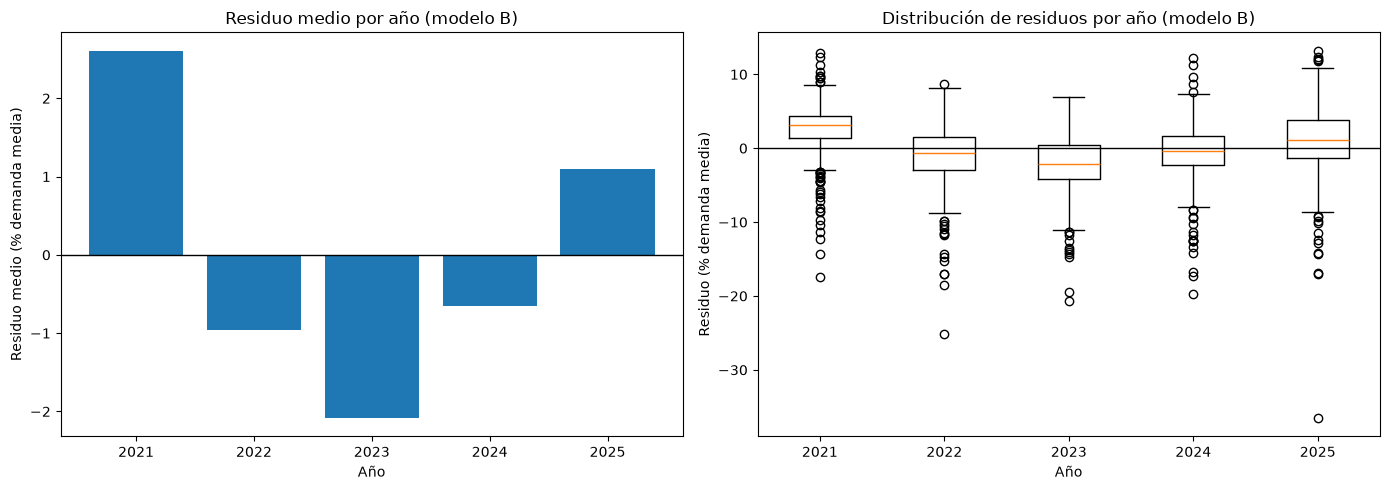

In [46]:
# ¿queda algo por año? residuos en % de la demanda media
residuos_pct = modelo_b.resid / demanda_media * 100
media_anio = residuos_pct.groupby(residuos_pct.index.year).mean()
print(media_anio.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(media_anio.index, media_anio.values)
axes[0].set_title("Residuo medio por año (modelo B)")
axes[0].set_ylabel("Residuo medio (% demanda media)")

anios = sorted(residuos_pct.index.year.unique())
axes[1].boxplot([residuos_pct[residuos_pct.index.year == a] for a in anios])
axes[1].set_xticks(range(1, len(anios) + 1), anios)
axes[1].set_title("Distribución de residuos por año (modelo B)")
axes[1].set_ylabel("Residuo (% demanda media)")

for ax in axes:
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Año")
plt.tight_layout()
plt.show()

Se puede ver claramente que el año influye en la demanda, por ello creo una nueva variable dummie que pueda explicar esto.

## Modelo C: + año

`demanda ~ hdd + cdd + C(dia_semana) + festivo + C(anio)`

El residuo medio por año del modelo B no es 0: cada año tiene su propio nivel de demanda por motivos que no son la temperatura. `C(anio)` le da a cada año su propio nivel (referencia: 2021).

In [47]:
FORMULA_C = formula_sistema("peninsular")   # demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)
modelo_c = smf.ols(FORMULA_C, data=df_peninsular).fit()
print(modelo_c.params.round(1))
print(f"R² = {modelo_c.rsquared:.3f}")
print(f"SD del residuo = {modelo_c.resid.std():,.0f} MWh".replace(",", " "))

Intercept             614118.0
C(dia_semana)[T.1]     18097.8
C(dia_semana)[T.2]     22074.5
C(dia_semana)[T.3]     21479.7
C(dia_semana)[T.4]     14193.5
C(dia_semana)[T.5]    -61175.0
C(dia_semana)[T.6]    -99975.9
C(anio)[T.2022]       -23238.7
C(anio)[T.2023]       -30504.5
C(anio)[T.2024]       -21181.0
C(anio)[T.2025]        -9877.8
hdd                    12467.0
cdd                    10945.5
festivo              -119157.2
dtype: float64
R² = 0.827
SD del residuo = 27 571 MWh


### Qué dice el modelo C

Los efectos de año, respecto a 2021 y ya descontados la temperatura y el calendario:

| Año | Coeficiente (MWh) | % demanda media |
|---|---|---|
| 2022 | −23 239 | −3,6 % |
| 2023 | −30 504 | −4,7 % |
| 2024 | −21 181 | −3,3 % |
| 2025 | −9 878 | −1,5 % |

- La demanda cae en 2022 y toca fondo en 2023, coincidiendo con la crisis energética (precios muy altos, más ahorro y menos actividad industrial). En 2024 empieza a recuperarse y en 2025 está casi al nivel de 2021. Es lo mismo que se veía en la media móvil de 365 días del EDA.
- **`C(anio)` es una caja negra**: recoge todo lo que cambia de un año a otro (precios, actividad económica, autoconsumo, turismo…), pero no dice cuál de esas cosas es la causa. Para esta pregunta no hace falta saberlo, solo que no se mezcle con la temperatura.
- El resto de coeficientes casi no se mueve respecto al modelo B. El festivo, por ejemplo, pasa de −120 183 a −119 157.

In [48]:
# ¿cambian las betas de temperatura al añadir controles?
modelos = {"A: hdd + cdd": modelo_a,
           "B: + día semana + festivo": modelo_b,
           "C: + año": modelo_c}

pd.DataFrame({
    nombre: {"β_hdd": m.params["hdd"], "β_cdd": m.params["cdd"], "R²": m.rsquared,
             "SD residuo (MWh)": m.resid.std()}
    for nombre, m in modelos.items()
}).T.round(3)

,β_hdd,β_cdd,R²,SD residuo (MWh)
A: hdd + cdd,11980.400,10731.468,0.304,55314.066
B: + día semana + festivo,12558.368,10879.449,0.801,29590.492
C: + año,12467.000,10945.528,0.827,27570.975


- **Las betas de temperatura son estables** en los tres modelos: β_hdd pasa de 11 980 a 12 558 y a 12 467, y β_cdd de 10 731 a 10 879 y a 10 946.
    - Los controles de calendario y año quitan ruido pero no corrigen el efecto de la temperatura, porque no están relacionados con ella. El efecto que mido no depende de estos controles.

- **El gran salto lo da B**: el R² pasa de 0,30 a 0,80 y la desviación típica del residuo de 55 000 a 30 000 MWh. 
    - C aporta menos (R² 0,83, residuo 27 600 MWh), pero quita el sesgo de nivel de cada año.

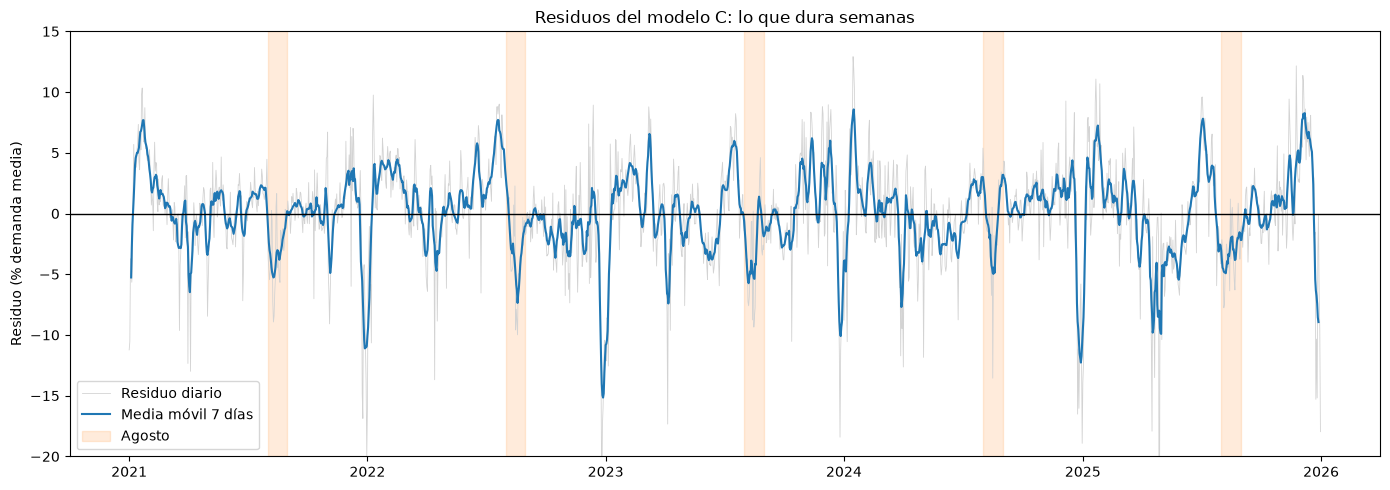

SD del residuo diario: 4.25 %
SD esperada de la media de 7 días si fueran independientes: 1.61 %
SD real de la media de 7 días: 3.29 %


In [49]:
# media móvil de 7 días: quita el ruido de un día para otro y deja lo que dura semanas
resid_c_pct = modelo_c.resid / demanda_media * 100
media_7d = resid_c_pct.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(resid_c_pct.index, resid_c_pct, color="lightgray", linewidth=0.6, label="Residuo diario")
ax.plot(media_7d.index, media_7d, color="tab:blue", linewidth=1.5, label="Media móvil 7 días")
for anio in resid_c_pct.index.year.unique():
    ax.axvspan(pd.Timestamp(f"{anio}-08-01"), pd.Timestamp(f"{anio}-08-31"), color="tab:orange", alpha=0.15,
               label="Agosto" if anio == resid_c_pct.index.year.min() else None)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylim(-20, 15)   # el apagón del 28/04/2025 (−37 %) queda fuera de escala
ax.set_ylabel("Residuo (% demanda media)")
ax.set_title("Residuos del modelo C: lo que dura semanas")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

# si los residuos fueran independientes, promediar 7 días dividiría su desviación típica por √7
print(f"SD del residuo diario: {resid_c_pct.std():.2f} %")
print(f"SD esperada de la media de 7 días si fueran independientes: {resid_c_pct.std() / np.sqrt(7):.2f} %")
print(f"SD real de la media de 7 días: {media_7d.std():.2f} %")

**Qué queda en los residuos del modelo C:**

La gráfica de residuos de los modelos A y B ya no enseña nada nuevo: no hay diente de sierra y el nivel de cada año está en 0. Por eso suavizo el residuo con una media de 7 días, que quita el ruido diario y deja solo lo que dura semanas. Se repiten tres cosas todos los años:

- **Julio por encima y agosto por debajo.** La media de 7 días está entre +1,4 % y +4,7 % en julio y entre −0,8 % y −3,2 % en agosto, con el mismo calor. Eso no es temperatura, son las vacaciones. El modelo no tiene ninguna variable para ellas y quedan como limitación.

- **Un hundimiento en cada Navidad**, de hasta −15 % (finales de diciembre de 2022). Son los días entre festivos que el modelo no conoce, y quedan como limitación.

- **Olas de una a varias semanas** por encima o por debajo de 0. Si los residuos fueran independientes, la media de 7 días tendría una desviación típica de 4,25 / √7 ≈ 1,6 %, pero la real es de 3,3 %: los errores de días seguidos se parecen. Eso afecta a la confianza en los β, que es lo siguiente.

## Autocorrelación y errores HAC
Hasta aquí he mirado **cuánto valen** β_hdd y β_cdd. Ahora toca ver **cuánta seguridad** tengo en esos valores (su error estándar y su intervalo de confianza).

OLS calcula el error estándar suponiendo que **cada día es independiente**: que el error de hoy no dice nada del de mañana. Pero en los residuos se ven "olas" de varias semanas por encima o por debajo de 0. 

Una ola de frío de 10 días se parece más a una sola observación que a 10 independientes. Por eso tengo **menos información de la que OLS cree**, y los intervalos clásicos salen **demasiado estrechos**.

**¿Cómo puedo saber qué ocurre y corregirlo?**

1. **Diagnóstico**: residuo de hoy contra el de ayer (si la nube parece una diagonal implica correlación), ACF (autocorrelación a 1, 2, … 30 días) y Durbin-Watson (2 = sin autocorrelación; cuanto más bajo, más autocorrelación positiva).

2. **Corrección**: errores estándar **HAC (Newey-West)**, que tienen en cuenta la correlación hasta `maxlags` días atrás. 
    - Elijo `maxlags` como el primer retardo en el que la ACF baja de 0,1 (lo hace `ajustar_modelo` en `src/modelo.py`): en la Península sale 14, dos semanas. 
    - HAC **no cambia los coeficientes**, solo el error estándar y el IC.

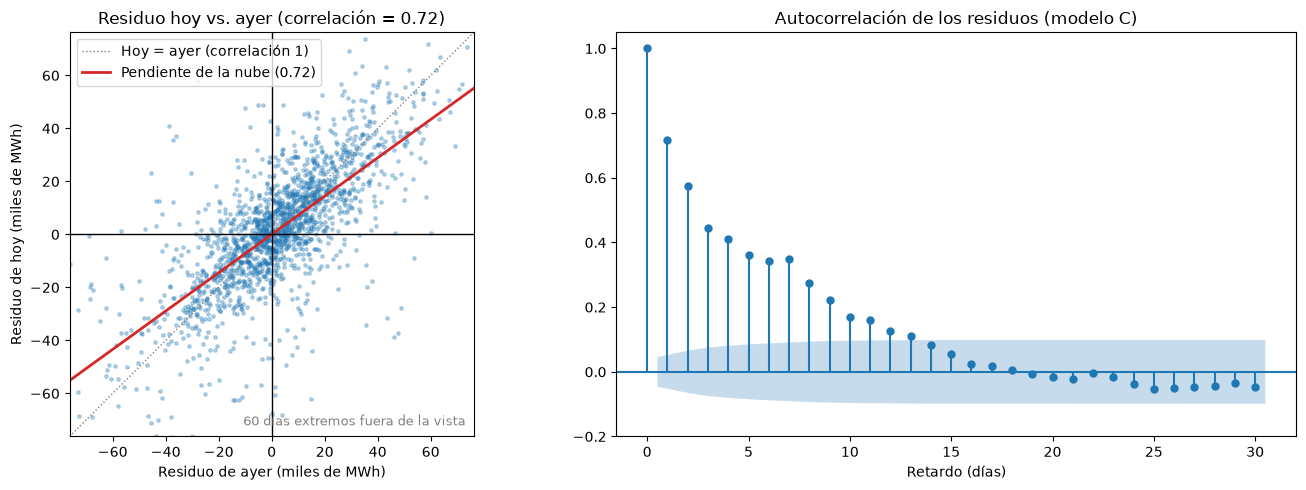

Durbin-Watson: 0.55


In [50]:
residuos = modelo_c.resid
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# residuo de hoy contra el de ayer: nube redonda = independientes, diagonal = autocorrelación
ayer = residuos.shift(1)
corr = residuos.corr(ayer)
lim = residuos.abs().quantile(0.98)                    # centro la vista: dejo fuera el 2 % más extremo
fuera = ((residuos.abs() > lim) | (ayer.abs() > lim)).sum()

axes[0].scatter(ayer / 1000, residuos / 1000, s=6, alpha=0.3)   # en miles de MWh
x = np.array([-lim, lim]) / 1000
axes[0].plot(x, x, color="gray", linestyle=":", linewidth=1, label="Hoy = ayer (correlación 1)")
axes[0].plot(x, corr * x, color="tab:red", linewidth=2, label=f"Pendiente de la nube ({corr:.2f})")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlim(-lim / 1000, lim / 1000)
axes[0].set_ylim(-lim / 1000, lim / 1000)
axes[0].set_aspect("equal")
axes[0].set_xlabel("Residuo de ayer (miles de MWh)")
axes[0].set_ylabel("Residuo de hoy (miles de MWh)")
axes[0].set_title(f"Residuo hoy vs. ayer (correlación = {corr:.2f})")
axes[0].text(0.98, 0.02, f"{fuera} días extremos fuera de la vista", transform=axes[0].transAxes,
             ha="right", va="bottom", fontsize=9, color="gray")
axes[0].legend(loc="upper left")

# ACF: la misma idea para 1, 2, ... 30 días atrás (fuera de la banda azul = significativa)
plot_acf(residuos, lags=30, ax=axes[1])
axes[1].set_xlabel("Retardo (días)")
axes[1].set_ylim(-0.2, 1.05)
axes[1].set_title("Autocorrelación de los residuos (modelo C)")

plt.tight_layout()
plt.show()

print(f"Durbin-Watson: {durbin_watson(residuos):.2f}")   # 2 = sin autocorrelación

Las tres pruebas dicen lo mismo:

- **La nube es diagonal**: los residuos positivos suelen ir seguidos de otro positivo y los negativos de otro negativo (correlación de 0,72).
- **La ACF** muestra que esa relación no se queda en el día anterior: sigue siendo clara hasta unos **14 días** antes y luego cae a ~0.
- **El Durbin-Watson es 0,55**, muy lejos de 2, que es lo que saldría si los días fueran independientes.

Los errores de días seguidos no son independientes, así que los errores estándar clásicos de OLS se quedan cortos. Eso motiva usar **errores estándar HAC**. No explican ni eliminan la relación entre días, porque los coeficientes son los mismos. Lo que hacen es tenerla en cuenta al calcular la incertidumbre, de forma que los intervalos de confianza reflejen la información que de verdad hay.

maxlags elegido con la ACF: 14

     β clásico    β HAC  SE clásico  SE HAC  ratio SE  t clásico  t HAC
hdd    12467.0  12467.0       229.7   574.8       2.5       54.3   21.7
cdd    10945.5  10945.5       222.8   577.2       2.6       49.1   19.0

Intervalo de confianza del efecto por grado-día (% de la demanda media):
    IC 95% clásico        IC 95% HAC       
               inf    sup        inf    sup
hdd          1.854  1.993      1.749  2.097
cdd          1.621  1.756      1.514  1.863


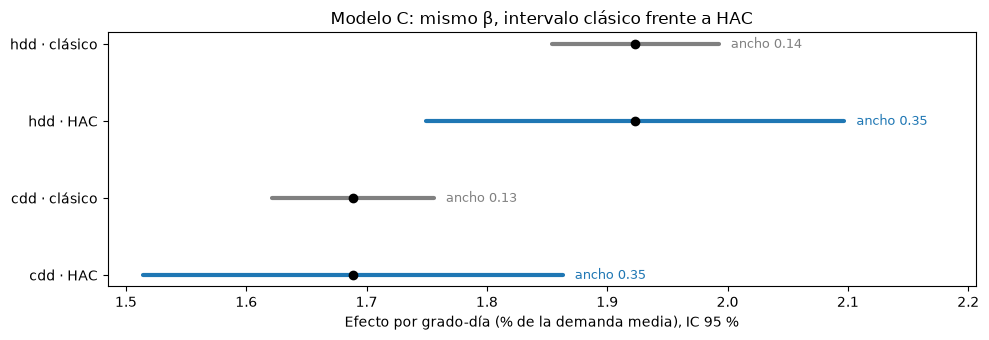

In [51]:
# mismo modelo C con errores HAC (Newey-West): los β no cambian, solo el SE
modelo_c_hac = ajustar_modelo(df_peninsular, FORMULA_C)
print(f"maxlags elegido con la ACF: {modelo_c_hac.cov_kwds['maxlags']}\n")

variables = ["hdd", "cdd"]
tabla_se = pd.DataFrame({
    "β clásico": modelo_c.params[variables],
    "β HAC": modelo_c_hac.params[variables],
    "SE clásico": modelo_c.bse[variables],
    "SE HAC": modelo_c_hac.bse[variables],
})
tabla_se["ratio SE"] = tabla_se["SE HAC"] / tabla_se["SE clásico"]
# t = β / SE: cuántas veces es el coeficiente más grande que su error (|t| > 3,3 equivale a p < 0,001)
tabla_se["t clásico"] = tabla_se["β clásico"] / tabla_se["SE clásico"]
tabla_se["t HAC"] = tabla_se["β HAC"] / tabla_se["SE HAC"]
print(tabla_se.round(1))

# intervalos de confianza al 95 %, en % de la demanda media
ic_clasico = modelo_c.conf_int().loc[variables] / demanda_media * 100
ic_hac = modelo_c_hac.conf_int().loc[variables] / demanda_media * 100
ic = pd.concat({"IC 95% clásico": ic_clasico, "IC 95% HAC": ic_hac}, axis=1)
ic.columns = ic.columns.set_levels(["inf", "sup"], level=1)
print("\nIntervalo de confianza del efecto por grado-día (% de la demanda media):")
print(ic.round(3))

# lo mismo en una gráfica: el punto (β) no se mueve, el intervalo se ensancha
fig, ax = plt.subplots(figsize=(10, 3.5))
filas = [(var, tipo, ic_tipo) for var in variables
         for tipo, ic_tipo in (("clásico", ic_clasico), ("HAC", ic_hac))]
for y, (var, tipo, ic_tipo) in enumerate(filas):
    inf, sup = ic_tipo.loc[var]
    color = "gray" if tipo == "clásico" else "tab:blue"
    ax.plot([inf, sup], [y, y], color=color, linewidth=3, solid_capstyle="round")
    ax.plot(modelo_c.params[var] / demanda_media * 100, y, "o", color="black", markersize=6)
    ax.text(sup + 0.01, y, f"ancho {sup - inf:.2f}", va="center", fontsize=9, color=color)
ax.set_yticks(range(len(filas)), [f"{var} · {tipo}" for var, tipo, _ in filas])
ax.invert_yaxis()
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] + 0.08)
ax.set_xlabel("Efecto por grado-día (% de la demanda media), IC 95 %")
ax.set_title("Modelo C: mismo β, intervalo clásico frente a HAC")
plt.tight_layout()
plt.show()

**Qué ha cambiado:**

- **Los coeficientes, nada.** β_hdd y β_cdd son idénticos en las dos columnas: HAC usa el mismo ajuste de OLS y solo recalcula la incertidumbre. En la gráfica, el punto negro no se mueve.

- **El error estándar se multiplica por unos 2,5** (de 230 a 575 MWh en `hdd` y de 223 a 577 en `cdd`). Eso equivale a tener unos 290 días independientes en vez de 1826: la información que de verdad aportan los datos cuando los días seguidos se parecen.

- **Los intervalos de confianza son unas 2,5 veces más anchos.** El de `hdd` pasa de 1,85–1,99 % a 1,75–2,10 %, y el de `cdd` de 1,62–1,76 % a 1,51–1,86 %. Con los errores clásicos el efecto parecía conocerse con una precisión que no tiene.

- **La conclusión no cambia.** El t pasa de ~54 a ~22 en `hdd` y de ~49 a ~19 en `cdd`: el coeficiente sigue siendo unas 20 veces mayor que su error y el p-valor sigue por debajo de 0,001. Que la temperatura importa es seguro; lo que cambia es cuánta precisión se le puede atribuir al número.

A partir de aquí todos los modelos van con errores HAC.

## Conclusiones

### La pregunta
¿Cuánto sube la demanda eléctrica diaria de la Península por cada grado que la temperatura se aleja de la de confort, separando el frío (HDD) del calor (CDD)? (2021-2025)

### Cómo he llegado al modelo
He ido de lo más simple a lo completo, añadiendo cada pieza solo cuando una gráfica mostraba que hacía falta:

| Modelo | Qué añado | Qué lo motivó | Efecto en la Península |
|---|---|---|---|
| A | `hdd + cdd` | La U de temperatura contra demanda: una recta no sirve | R² = 0,30 |
| B | `C(dia_semana) + festivo` | Dientes de sierra semanales y valles en festivos en los residuos | R² = 0,80; las betas casi no cambian (el día de la semana no está relacionado con la temperatura) |
| C | `C(anio)` | Residuo medio distinto de 0 según el año (2023 el más bajo) | R² = 0,83; betas estables |
| C con HAC | Errores HAC (`maxlags` según la ACF: 14) | Residuos autocorrelacionados (DW = 0,55): los errores estándar clásicos eran demasiado pequeños| Mismas betas; error estándar unas 2,5 veces mayor |

Por el camino también corregí `festivo`, que contaba dos veces los festivos que caen en fin de semana.

### Resultado: modelo C con errores HAC

| | Efecto por grado-día (% de la demanda media) | IC 95 % HAC | MWh por grado-día |
|---|---|---|---|
| Frío (HDD) | 1,92 % | 1,75 % – 2,10 % | 12 467 |
| Calor (CDD) | 1,69 % | 1,51 % – 1,86 % | 10 946 |

### Qué me dice
- **La temperatura importa mucho**: cada grado-día de frío sube la demanda un 1,9 % y cada grado-día de calor un 1,7 %. Los dos efectos son claramente significativos incluso con errores HAC.
- **El frío pesa algo más que el calor**, y la diferencia es significativa (test de β_hdd − β_cdd con HAC, p ≈ 0,007). Con cautela: es justo el efecto que más depende de cómo se trate la estacionalidad de invierno (ver limitaciones).
- **Los resultados son estables**: β_hdd y β_cdd casi no se mueven al añadir el calendario y el año.

### Limitaciones
- **Estacionalidad que no es temperatura sin controlar**: agosto queda por debajo de la predicción y la Navidad y la Semana Santa también.
- **Festivos incompletos**: solo uso los nacionales. Faltan los autonómicos (Jueves Santo, el 26/12/2022…), los puentes y los días "casi festivos" (24 y 31 de diciembre), que siguen apareciendo entre los peores residuos.
- **Outliers sin tratar**: el apagón del 28/04/2025 es el peor residuo de todo el periodo.
- **T_base fija** (17 °C), elegida en el EDA y no estimada.
- **Efecto lineal**: supongo que cada grado-día suma lo mismo. Un día extremo podría pesar más que uno suave, y la inercia térmica (el calor de ayer) no está en el modelo.
- **Autoconsumo**: la demanda de REE no ve la energía de las placas solares en tejados, que crece cada año. `C(anio)` recoge su nivel, pero no cómo cambia según la temperatura.
- **Modelo explicativo**: mide sensibilidades, no predice la demanda ni el efecto del cambio climático a largo plazo.

### Posibles mejoras
- Variables de calendario concretas (agosto, Navidad, Semana Santa, puentes) para separar la estacionalidad sin quitarle variación a la temperatura.
- Festivos autonómicos ponderados por población.
- Estimar T_base probando varios valores y quedándome con el que mejor ajuste.
- Añadir la temperatura de días anteriores (retardos de HDD/CDD) para recoger la inercia térmica.
- Probar efectos no lineales (por ejemplo, HDD² y CDD²) para los días extremos.